# 04 Double Sérsic PSF-Convolved Mock

Validate recovery of bulge+disk parameters using CompositeModel, ConvolvedModel, and Dynesty.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from baymorph import (
    CompositeModel,
    ConvolvedModel,
    DynestyFitter,
    GaussianPSF,
    Parameter,
    ParameterSet,
    SersicModel,
    add_gaussian_noise,
    make_constant_noise_map,
    plot_data_model_residual,
)

In [2]:
true_flux_bulge = 3000
true_re_bulge = 3

bulge = SersicModel(
    flux=true_flux_bulge,
    re=true_re_bulge,
    n=4,
    q=0.8,
    theta=0.0,
    x0=30,
    y0=30,
)

In [3]:
true_flux_disk = 7000
true_re_disk = 12

disk = SersicModel(
    flux=true_flux_disk,
    re=true_re_disk,
    n=1,
    q=0.8,
    theta=0.0,
    x0=30,
    y0=30,
)

In [4]:
true_model = CompositeModel([bulge, disk])

psf = GaussianPSF(fwhm=3.0)

true_model_psf = ConvolvedModel(
    true_model,
    psf,
)

In [5]:
clean_image = true_model_psf.render(shape=(60, 60))

data = add_gaussian_noise(
    clean_image,
    sigma=1.0,
    seed=42,
)

noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

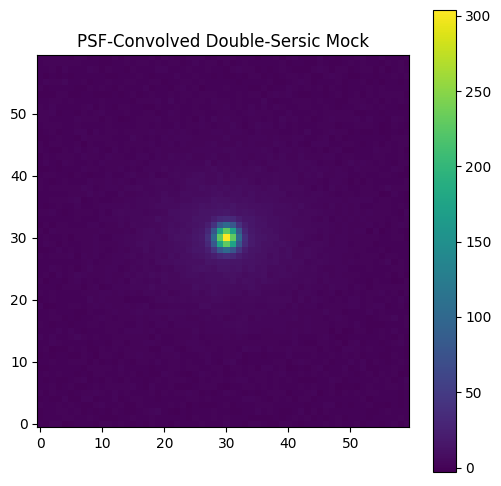

In [6]:
plt.figure(figsize=(6, 6))
plt.imshow(data, origin="lower")
plt.colorbar()
plt.title("PSF-Convolved Double-Sersic Mock")
plt.show()

In [7]:
print("Bulge flux:", true_flux_bulge)
print("Bulge re:", true_re_bulge)

print()

print("Disk flux:", true_flux_disk)
print("Disk re:", true_re_disk)

Bulge flux: 3000
Bulge re: 3

Disk flux: 7000
Disk re: 12


In [8]:
def model_factory(
    flux_bulge,
    re_bulge,
    flux_disk,
    re_disk,
):
    bulge = SersicModel(
        flux=flux_bulge,
        re=re_bulge,
        n=4,
        q=0.8,
        theta=0.0,
        x0=30,
        y0=30,
    )

    disk = SersicModel(
        flux=flux_disk,
        re=re_disk,
        n=1,
        q=0.8,
        theta=0.0,
        x0=30,
        y0=30,
    )

    composite = CompositeModel([bulge, disk])

    return ConvolvedModel(
        composite,
        psf,
    )

In [9]:
parameters = ParameterSet(
    [
        Parameter("flux_bulge", 500, 6000),
        Parameter("re_bulge", 1, 8),
        Parameter("flux_disk", 3000, 12000),
        Parameter("re_disk", 5, 20),
    ]
)

In [10]:
fitter = DynestyFitter(
    model_factory=model_factory,
    data=data,
    noise=noise,
    parameters=parameters,
)

In [11]:
result = fitter.run(
    nlive=150,
    sample="rwalk",
    print_progress=True,
)

iter: 2774 | +150 | bound: 16 | nc: 1 | ncall: 59724 | eff(%):  4.908 | loglstar:   -inf < -5108.027 <    inf | logz: -5124.585 +/-  0.317 | dlogz:  0.001 >  0.159                                   

In [12]:
result.best_parameters

{'flux_bulge': 2995.6957015185963,
 're_bulge': 2.8857915807850185,
 'flux_disk': 6969.834679042503,
 're_disk': 12.039312483686448}

In [13]:
for parameter in [
    "flux_bulge",
    "re_bulge",
    "flux_disk",
    "re_disk",
]:
    print(parameter)
    print(result.summary(parameter))
    print()

flux_bulge
{'q16': 2931.778303553719, 'median': 2987.020172561612, 'q84': 3059.9519716452355}

re_bulge
{'q16': 2.1537282520110845, 'median': 2.7942937003480037, 'q84': 3.4343406222896062}

flux_disk
{'q16': 6896.508138607529, 'median': 6964.303168086408, 'q84': 7025.078916995489}

re_disk
{'q16': 11.892287873423633, 'median': 12.02511908623528, 'q84': 12.176170945014414}



In [14]:
best = result.best_parameters

best_model = model_factory(
    flux_bulge=best["flux_bulge"],
    re_bulge=best["re_bulge"],
    flux_disk=best["flux_disk"],
    re_disk=best["re_disk"],
)

best_image = best_model.render(
    shape=data.shape,
)

(<Figure size 1800x600 with 6 Axes>,
 array([<Axes: title={'center': 'Data'}>,
        <Axes: title={'center': 'Model'}>,
        <Axes: title={'center': 'Residual'}>], dtype=object))

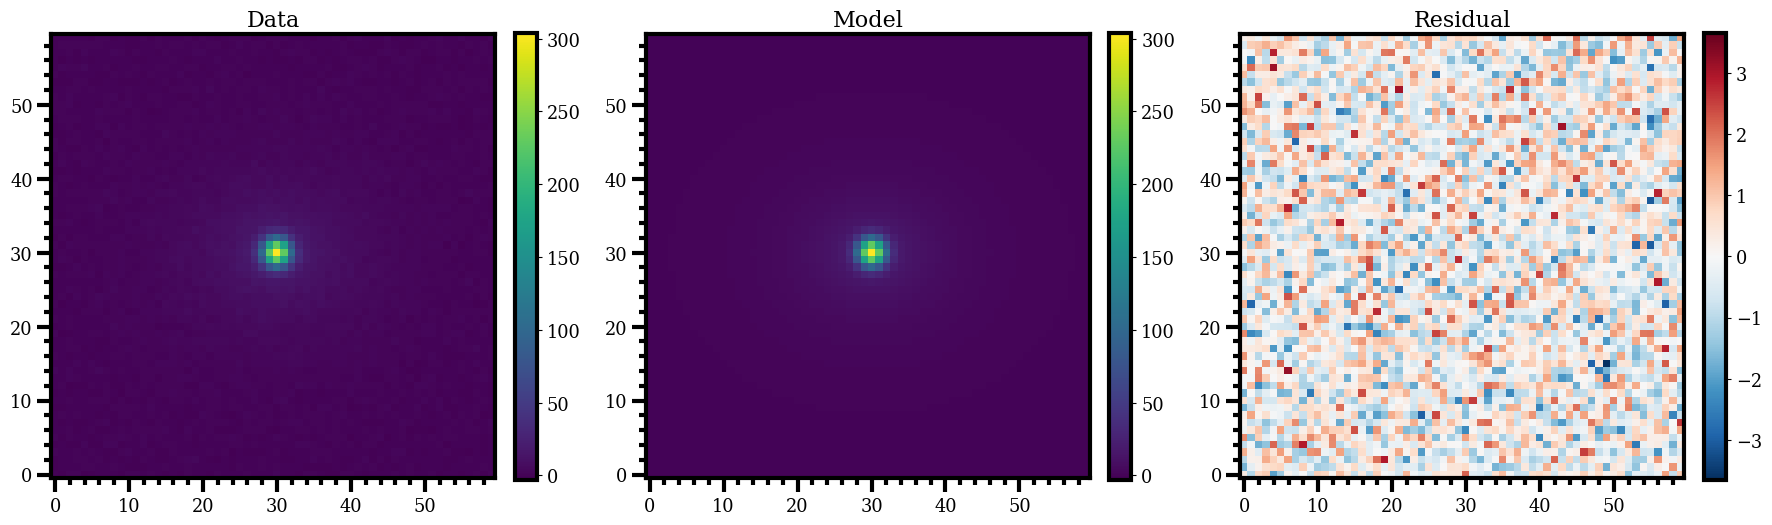

In [15]:
plot_data_model_residual(
    data,
    best_image,
)

In [16]:
print("Bulge flux")
print(true_flux_bulge, best["flux_bulge"])

print()
print("Bulge re")
print(true_re_bulge, best["re_bulge"])

print()
print("Disk flux")
print(true_flux_disk, best["flux_disk"])

print()
print("Disk re")
print(true_re_disk, best["re_disk"])

Bulge flux
3000 2995.6957015185963

Bulge re
3 2.8857915807850185

Disk flux
7000 6969.834679042503

Disk re
12 12.039312483686448


In [17]:
print(
    "CompositeModel + ConvolvedModel successfully recover "
    "flux and effective radius for both Sérsic components."
)

CompositeModel + ConvolvedModel successfully recover flux and effective radius for both Sérsic components.
